# Part 1: Import Packages

In [1]:
%pip install ucimlrepo scikit-optimize

In [2]:
import numpy as np
import pandas as pd
import torch

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import torch.nn as nn

import torch.nn.functional as F

from sklearn.calibration import CalibratedClassifierCV

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score, roc_curve
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.calibration import CalibrationDisplay
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

# Part 2: Importing Dataset and Preprocessing

Both datasets are loaded from the UCI repository as a feature table plus a target column. Spambase has 4,601 rows and 57 numeric features. Online Shoppers has 12,330 rows and 17 features, 7 of which are categorical.

## 2.2.1. Spam Dataset

In [3]:
# fetch spam dataset
spambase = fetch_ucirepo(id=94)
spam_df = pd.concat((spambase.data.features, spambase.data.targets), axis=1)

# variable information
print(spambase.variables)

                          name     role        type demographic  \
0               word_freq_make  Feature  Continuous        None   
1            word_freq_address  Feature  Continuous        None   
2                word_freq_all  Feature  Continuous        None   
3                 word_freq_3d  Feature  Continuous        None   
4                word_freq_our  Feature  Continuous        None   
5               word_freq_over  Feature  Continuous        None   
6             word_freq_remove  Feature  Continuous        None   
7           word_freq_internet  Feature  Continuous        None   
8              word_freq_order  Feature  Continuous        None   
9               word_freq_mail  Feature  Continuous        None   
10           word_freq_receive  Feature  Continuous        None   
11              word_freq_will  Feature  Continuous        None   
12            word_freq_people  Feature  Continuous        None   
13            word_freq_report  Feature  Continuous        Non

All features are numeric with no missing values.

## 2.1.2. Fetch Online Shoppers Dataset

In [4]:
# fetch online shoppers dataset
online_shoppers_purchasing_intention_dataset = fetch_ucirepo(id=468)
shoppers_df = pd.concat((online_shoppers_purchasing_intention_dataset.data.features,
                        online_shoppers_purchasing_intention_dataset.data.targets), axis=1)

# variable information
print(online_shoppers_purchasing_intention_dataset.variables)

                       name     role         type demographic description  \
0            Administrative  Feature      Integer        None        None   
1   Administrative_Duration  Feature      Integer        None        None   
2             Informational  Feature      Integer        None        None   
3    Informational_Duration  Feature      Integer        None        None   
4            ProductRelated  Feature      Integer        None        None   
5   ProductRelated_Duration  Feature   Continuous        None        None   
6               BounceRates  Feature   Continuous        None        None   
7                 ExitRates  Feature   Continuous        None        None   
8                PageValues  Feature      Integer        None        None   
9                SpecialDay  Feature      Integer        None        None   
10                    Month  Feature  Categorical        None        None   
11         OperatingSystems  Feature      Integer        None        None   

## 2.2. Preprocessing Dataset

### 2.2.1. Spam Dataset

In [5]:
# See the first 5 spam samples
spam_df.head(5)

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,Class
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [6]:
# See data types in each column
spam_df.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4601 non-null   float64
 1   word_freq_address           4601 non-null   float64
 2   word_freq_all               4601 non-null   float64
 3   word_freq_3d                4601 non-null   float64
 4   word_freq_our               4601 non-null   float64
 5   word_freq_over              4601 non-null   float64
 6   word_freq_remove            4601 non-null   float64
 7   word_freq_internet          4601 non-null   float64
 8   word_freq_order             4601 non-null   float64
 9   word_freq_mail              4601 non-null   float64
 10  word_freq_receive           4601 non-null   float64
 11  word_freq_will              4601 non-null   float64
 12  word_freq_people            4601 non-null   float64
 13  word_freq_report            4601 

In [7]:
# Check if there are any duplicate rows in the dataset
spam_df[spam_df.duplicated(keep=False)]

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,Class
24,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.196,0.000,0.392,0.196,0.0,5.466,22,82,1
26,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.196,0.000,0.392,0.196,0.0,5.466,22,82,1
101,0.0,0.0,0.64,0.0,0.0,0.64,0.0,0.0,0.0,0.0,...,0.094,0.189,0.284,0.662,0.000,0.0,10.068,131,292,1
102,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.305,0.611,0.000,1.529,0.000,0.0,5.500,22,66,1
103,0.0,0.0,0.64,0.0,0.0,0.64,0.0,0.0,0.0,0.0,...,0.094,0.189,0.284,0.662,0.000,0.0,10.068,131,292,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4439,0.0,0.0,0.74,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.036,0.147,0.000,0.147,0.000,0.0,2.587,55,282,0
4441,0.0,0.0,0.74,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.036,0.147,0.000,0.147,0.000,0.0,2.587,55,282,0
4537,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.0,1.000,1,6,0
4541,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.0,1.000,1,2,0


Duplicate rows are removed because identical rows can land in both train and test, which would make test performance look better than it is.

In [8]:
# Remove duplicated rows
spam_df.drop_duplicates(inplace=True)

### 2.2.2. Online Shoppers Dataset

In [9]:
# See the first 5 spam samples
shoppers_df.head(5)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [10]:
# See data types in each column
shoppers_df.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

Same as `2.2.1.`, the `info` table indicates that there are **no null values** in the dataset.

In [11]:
# Check if there are any duplicate rows in the dataset
shoppers_df[shoppers_df.duplicated(keep=False)]

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11934,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,2,New_Visitor,False,False
11938,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,4,1,Returning_Visitor,True,False
12159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,3,Returning_Visitor,False,False
12180,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,13,9,20,Returning_Visitor,False,False


In [12]:
# Remove duplicated rows
shoppers_df.drop_duplicates(inplace=True)

In [13]:
# See the number of unique values for each categorical feature in the dataset
shoppers_cat_features = ['Month', 'VisitorType', 'OperatingSystems', 'Browser',
                         'Region', 'TrafficType', 'Weekend']
for col in shoppers_cat_features:
    print(f'{col}: {shoppers_df[col].nunique():,}')

# Numerical features for scaling
shoppers_num_features = [col for col in shoppers_df.columns
                         if col not in shoppers_cat_features and col != 'Revenue']

Month: 10
VisitorType: 3
OperatingSystems: 8
Browser: 13
Region: 9
TrafficType: 20
Weekend: 2


Since `LogisticRegression` can't handle categorical features (even if they have numeric values), we need to **one-hot encode** these features. The seven categorical features (`Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `Weekend`) have between 2 and 20 levels, so one-hot encoding is cheap.

# Part 3: Uncalibrated Modeling

For each dataset we fit three uncalibrated models with default hyperparameters, then tune each with `BayesSearchCV`, and compare train and test Brier and log loss. A single seed (42) is used throughout for reproducibility.

In [14]:
SEED = 42

## 3.1. Custom Functions

### 3.1.1. Estimator Pipeline

Preprocessing (one-hot encoding and scaling) is wrapped in a `Pipeline` with the classifier. During cross-validation, the encoder and scaler are refit on each training fold only, so no information from the validation fold leaks into preprocessing.

In [15]:
def create_pipeline(model, categorical_features, numerical_features, drop=None):
    # Set up column transformer to encode categorical features and
    # scale numerical features
    preprocessor = ColumnTransformer(
        transformers=[
            ('cat', OneHotEncoder(handle_unknown='ignore', drop=drop), categorical_features),
            ('num', StandardScaler(), numerical_features)
        ],
        remainder='passthrough',
        force_int_remainder_cols=False
    )
    # Set up pipeline with column transformer and inputted model
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    return pipeline

### 3.1.2. Evaluate Models

Reports Brier score and log loss on both train and test sets. A large train-test gap indicates overfitting. Test scores are what we use to compare models. Additionally, draw the ROC curves for later comparison.

In [16]:
def eval_model(model, X_train, X_test, y_train, y_test):
    # Evaluate model performance on training set
    # Get predicted probabilities for Class 1
    y_pred_train = model.predict_proba(X_train)[:, 1]

    print("----------Model Performance on Train Set----------")
    print(f"Brier: {brier_score_loss(y_train, y_pred_train):.4f}")
    print(f"Log loss: {log_loss(y_train, y_pred_train):.4f}")

    # Evaluate model performance on test set
    y_pred_test = model.predict_proba(X_test)[:, 1]

    print("----------Model Performance on Test Set----------")
    print(f"Brier: {brier_score_loss(y_test, y_pred_test):.4f}")
    print(f"Log loss: {log_loss(y_test, y_pred_test):.4f}")

    # ROC curve plot
    auc_score = roc_auc_score(y_test, y_pred_test)
    fpr, tpr, threshold = roc_curve(y_test, y_pred_test)

    plt.figure(figsize=(6, 6))
    plt.plot(fpr, tpr, label=f"Model ROC Curve (AUC = {auc_score:.3f})", color="#9BB8D3")
    plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Guessing (AUC = 0.500)")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend(loc="lower right", frameon=False)
    plt.tight_layout()
    plt.show()

## 3.2. Spam Dataset

### 3.2.0. Train-Test Split

In [17]:
X_spam = spam_df.drop('Class', axis=1)
y_spam = spam_df['Class']

# Check class balance
print(f"{y_spam.mean():.2%} spam")

39.88% spam


Due to the class imbalance, we will perform the train-test split on `spam_df` with stratify.

In [18]:
X_spam_train, X_spam_test, y_spam_train, y_spam_test = train_test_split(X_spam, y_spam, test_size=0.2, random_state=SEED, stratify=y_spam)

# Check class balance after split
print(f"Training set: {len(X_spam_train)} rows, {y_spam_train.mean():.2%} spam")
print(f"Testing set: {len(X_spam_test)} rows, {y_spam_test.mean():.2%} spam")

Training set: 3368 rows, 39.88% spam
Testing set: 842 rows, 39.90% spam


Spam is about 40% positive, so we use an 80/20 stratified split to keep the class ratio equal in both sets. The test set is roughly 840 rows, which limits how finely we can distinguish models.

### 3.2.1. Logistic Regression

The baseline uses `class_weight='balanced'` and default regularization (L2 with strength C=1). Note that `class_weight='balanced'` deliberately shifts probabilities toward the minority class, which can work against calibration.

Logistic Regression's default parameters:
- `max_iter=100`
- `penalty='l2'`
- `C=1.0` (regularization strength)
- `solver='lbfgs'` (solver for l2)
- `class_weight=None`

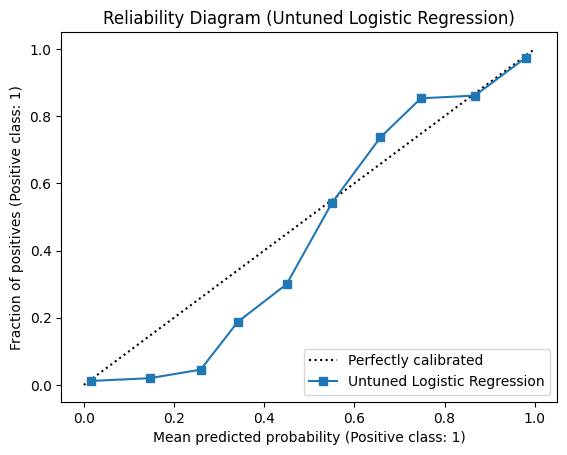

In [19]:
# Set up pipeline
spam_lr_untuned = create_pipeline(LogisticRegression(random_state=SEED, class_weight='balanced', max_iter=1000),
                                  [], X_spam_train.columns, drop='first')

# Train the baseline logistic regression model on training data
spam_lr_untuned.fit(X_spam_train, y_spam_train)

# Draw reliability diagram on the test set
CalibrationDisplay.from_estimator(spam_lr_untuned, X_spam_test, y_spam_test, n_bins=10, name="Untuned Logistic Regression")

plt.title("Reliability Diagram (Untuned Logistic Regression)")
plt.show()

----------Model Performance on Train Set----------
Brier: 0.0587
Log loss: 0.2127
----------Model Performance on Test Set----------
Brier: 0.0558
Log loss: 0.2089


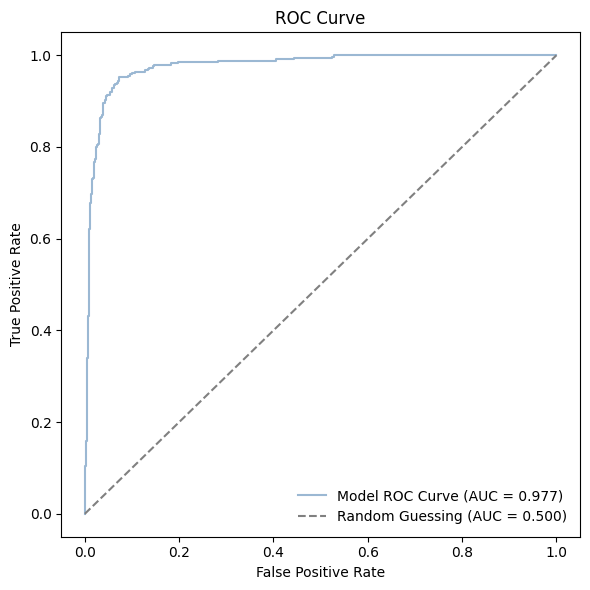

In [20]:
# Evaluate untuned Logistic Regression performance on dataset
eval_model(spam_lr_untuned, X_spam_train, X_spam_test, y_spam_train, y_spam_test)

### Evaluation of Untuned Logistic Regression

**Untuned LR result**:
- Train Set: Brier = **0.0587**, Log loss = **0.2127**
- Test Set: Brier = **0.0558**, Log loss = **0.2089**
- ROC AUC Score: **0.977** on the test set, indicating an extremely high ability to separate the two classes.

The reliability diagram shows a moderately well-calibrated curve that roughly follows the diagonal. However, because `class_weight='balanced'` was used, it tends to *overpredict* the true probability slightly in some regions to compensate for class imbalance (i.e., boosting the probabilities of the smaller class), pushing the curve slightly below the diagonal line. Note that the curve goes above the diagonal when the predicted probability is above 0.5.

With an AUC of 0.977, the ROC curve shows that the model is highly effective. Since the gap between training and testing performance is negligible, there are no signs of overfitting. The high performance is a result of the features being highly distinct and separable.

#### Hyperparameter Tuning

For tuning the models using cross-validation, we prefer `BayesSearchCV` over `GridSearchCV` for a few reasons:
- Uses a probabilistic model to learn from previous trial results to choose better hyperparameters with fewer total iterations
- Saves time and compute costs by concentrating on high-performing (high scores) regions
- Scales better with more hyperparameter (as the costs doesn't multiply with every additional parameter like a grid does)
- Can search through a continuous range (e.g., Integer(1, 10) searches {1, 2, ..., 10})

Hence, we will use `BayesSearchCV` to tune the hyperparameters `max_iter`, `C` (regularization strength), `penalty`, `solver`, and `class_weight`.

In [21]:
# Define the pipeline
lr_pipeline = create_pipeline(LogisticRegression(random_state=SEED),
                                [], X_spam_train.columns, drop='first')

# Define the search space
search_space = {
    'classifier__max_iter': Integer(100, 5000),
    'classifier__C': Real(1e-4, 1e3, prior='log-uniform'),
    'classifier__penalty': Categorical(['l1', 'l2']),
    'classifier__solver': Categorical(['liblinear', 'saga']),
    'classifier__class_weight': Categorical(['balanced', None])
}

# Set up and run BayesSearchCV
opt = BayesSearchCV(estimator=lr_pipeline, search_spaces=search_space,
                       n_iter=15, cv=5, scoring='neg_log_loss', random_state=SEED, n_jobs=-1)
opt.fit(X_spam_train, y_spam_train)

# Output tuning results
print(f"Best CV Log Loss: {abs(opt.best_score_):.4f}")
print("Best Hyperparameters:", opt.best_params_)

Best CV Log Loss: 0.2470
Best Hyperparameters: OrderedDict({'classifier__C': 0.22222301088730523, 'classifier__class_weight': None, 'classifier__max_iter': 5000, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'})


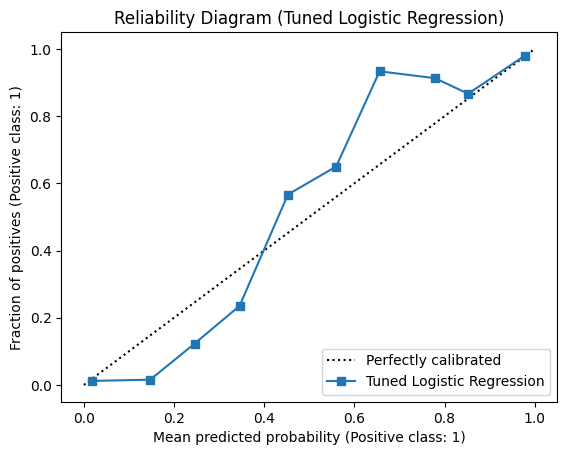

In [22]:
spam_lr_tuned = opt.best_estimator_

# Draw reliability diagram
CalibrationDisplay.from_estimator(spam_lr_tuned, X_spam_test, y_spam_test, n_bins=10, name="Tuned Logistic Regression")

plt.title("Reliability Diagram (Tuned Logistic Regression)")
plt.show()

----------Model Performance on Train Set----------
Brier: 0.0597
Log loss: 0.2134
----------Model Performance on Test Set----------
Brier: 0.0567
Log loss: 0.2115


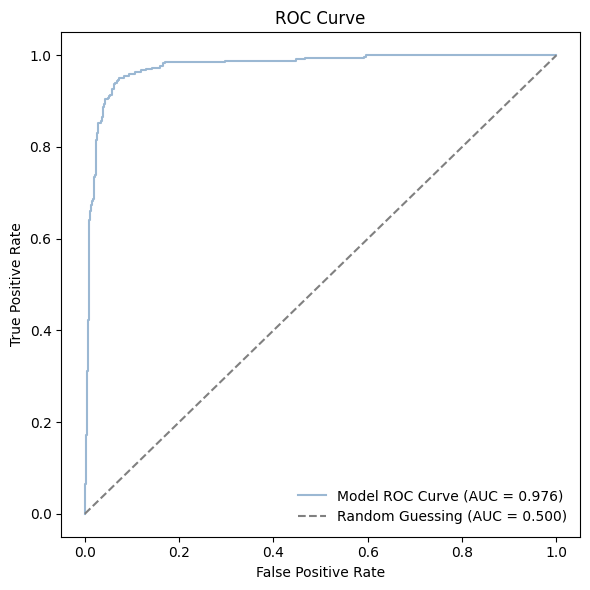

In [23]:
# Evaluate tuned Logistic Regression performance on dataset
eval_model(spam_lr_tuned, X_spam_train, X_spam_test, y_spam_train, y_spam_test)

### Evaluation of Tuned Logistic Regression

**Tuned LR result**:
- Train Set: Brier = **0.0597**, Log loss = **0.2134**
- Test Set: Brier = **0.0567**, Log loss = **0.2115**
- Best CV Log Loss: **0.2470**
- Best Hyperparameters: `max_iter=5000`, `C ≈ 0.222`, `class_weight=None`, `penalty='l1'`, `solver='liblinear'`
- ROC AUC Score: **0.976**

The reliability diagram for the tuned model shows a shift. Because the hyperparameter optimization selected `class_weight=None` and a low regularization strength `C` with L1 penalty, the model's output probabilities are generally pushed closer to the prior class distribution (around 40%). This results in some grouping or overconfidence/underconfidence in specific bins, showing a slightly more jagged calibration curve compared to the baseline.

The ROC AUC score of 0.976 is virtually identical to the untuned model, demonstrating that tuning the regularization structure didn't change the separability of the classes, but did adjust the calibration parameters.

### 3.2.2. Random Forest

Unlike Logistic Regression, Random Forest can capture non-linear relationships and the interection between the features, allowing more flexibility. However, this flexibility can also leads to overfitting.

Random Forest's default parameters:
- `n_estimator=100`
- `max_features='sqrt'`
- `max_depth=None`
- `min_samples_split=2`
- `min_samples_leaf=1`

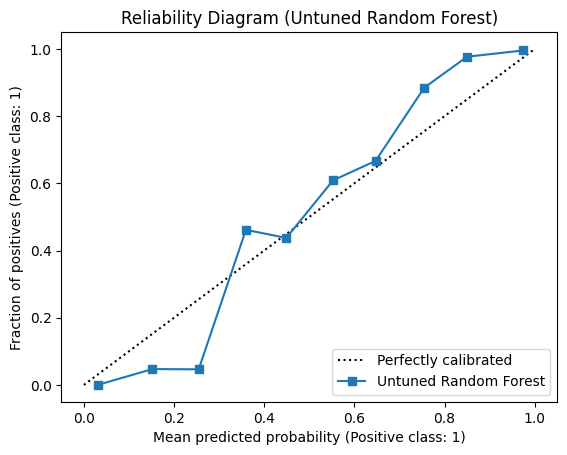

In [24]:
# Set up pipeline
spam_rf_untuned = create_pipeline(RandomForestClassifier(random_state=SEED),
                            [], X_spam_train.columns)

# Train the baseline Random Forest model on training data
spam_rf_untuned.fit(X_spam_train, y_spam_train)

# Draw reliability diagram on the test set
CalibrationDisplay.from_estimator(spam_rf_untuned, X_spam_test, y_spam_test, n_bins=10, name="Untuned Random Forest")

plt.title("Reliability Diagram (Untuned Random Forest)")
plt.show()

----------Model Performance on Train Set----------
Brier: 0.0067
Log loss: 0.0476
----------Model Performance on Test Set----------
Brier: 0.0425
Log loss: 0.1582


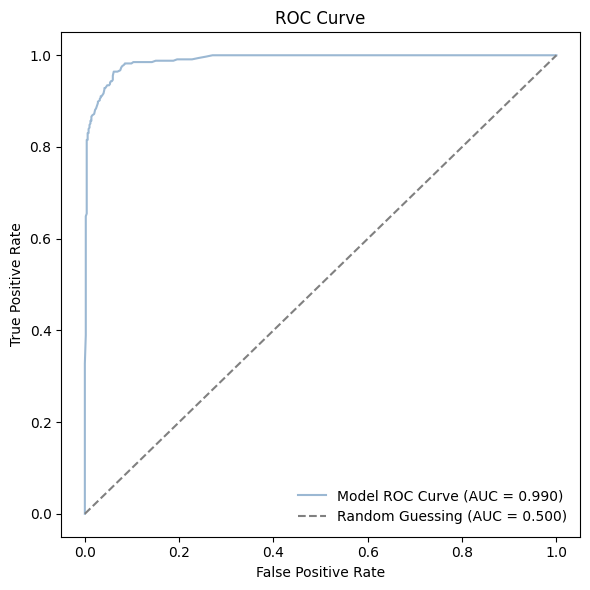

In [25]:
# Evaluate untuned Random Forest performance on dataset
eval_model(spam_rf_untuned, X_spam_train, X_spam_test, y_spam_train, y_spam_test)

### Evaluation of Untuned Random Forest

**Untuned RF result**:
- Train Set: Brier = **0.0067**, Log loss = **0.0476**
- Test Set: Brier = **0.0425**, Log loss = **0.1582**
- ROC AUC Score: **0.990** on the test set.

The gap between the training and testing Log Loss confirms that Random Forest exhibits some overfitting, but it is not a strong evidence as the test sample is small (~840 samples), causing some noise in the evaluation.

The untuned Random Forest exhibits a somewhat "S-Shape" (sigmoid) behavior. Because the bagging of deep decision trees make predictions by averaging tree-level votes, they are structurally biased against producing extreme probabilities close to 0 or 1 (the average rarely lands exactly at 0 or 1). The reliability curve sits below the diagonal for lower predicted probabilities and above the diagonal for higher predicted probabilities. Despite this calibration bias, it generalizes incredibly well with a massive test AUC of 0.990, which is an improvement over the Logistic Regression models.

#### Hyperparameter Tuning

Similar to Logistic Regression, we will tune Random Forest using `BayesSearchCV` on the hyperparameters `n_estimators`, `max_features`, `max_depth`, `min_samples_split`, and `min_samples_leaf`.

In [26]:
# Define the pipeline
rf_pipeline = create_pipeline(RandomForestClassifier(random_state=SEED),
                            [], X_spam_train.columns)

# Define a search space
search_space = {
    'classifier__n_estimators': Integer(100, 500),
    'classifier__max_features': Categorical(['sqrt', 'log2', None]),
    'classifier__max_depth': Categorical([None, 10, 15, 20, 30]),
    'classifier__min_samples_split': Integer(2, 10),
    'classifier__min_samples_leaf': Integer(1, 4)
}

# Set up and run BayesSearchCV
opt = BayesSearchCV(estimator=rf_pipeline, search_spaces=search_space,
                    n_iter=15, cv=5, scoring='neg_log_loss', random_state=SEED, n_jobs=-1)
opt.fit(X_spam_train, y_spam_train)

# Print tuning results
print(f"Best CV Log Loss: {abs(opt.best_score_):.4f}")
print("Best Hyperparameters found:", opt.best_params_)

Best CV Log Loss: 0.1801
Best Hyperparameters found: OrderedDict({'classifier__max_depth': None, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 460})


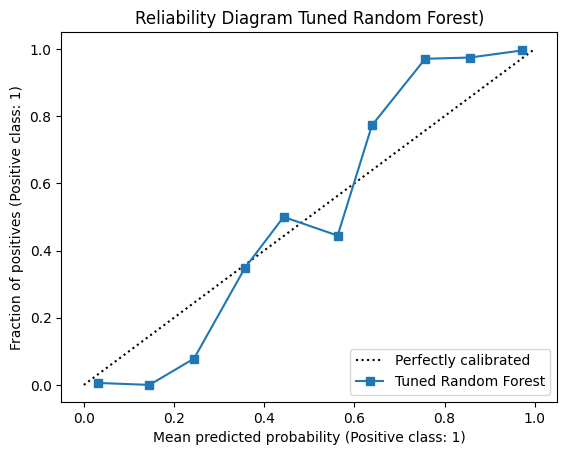

In [27]:
spam_rf_tuned = opt.best_estimator_

# Draw reliability diagram
CalibrationDisplay.from_estimator(spam_rf_tuned, X_spam_test, y_spam_test, n_bins=10, name="Tuned Random Forest")

plt.title("Reliability Diagram Tuned Random Forest)")
plt.show()

----------Model Performance on Train Set----------
Brier: 0.0063
Log loss: 0.0483
----------Model Performance on Test Set----------
Brier: 0.0424
Log loss: 0.1605


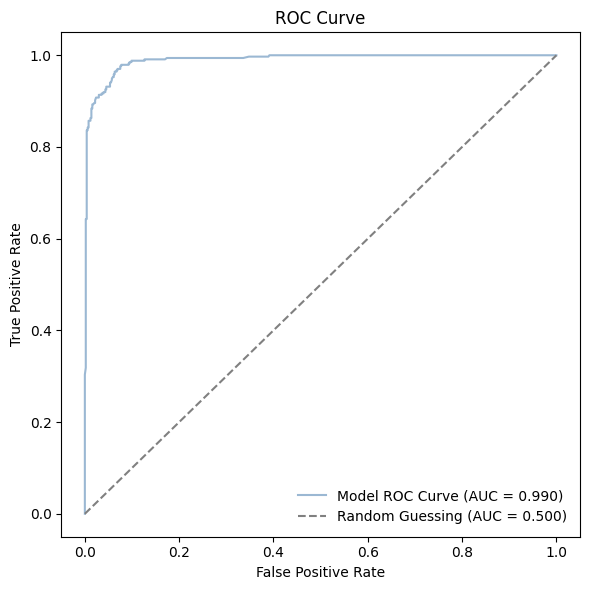

In [28]:
# Evaluate tuned Random Forest performance on dataset
eval_model(spam_rf_tuned, X_spam_train, X_spam_test, y_spam_train, y_spam_test)

### Evaluation of Tuned Random Forest

**Tuned RF result**:
- Train Set: Brier = **0.0063**, Log loss = **0.0483**
- Test Set: Brier = **0.0424**, Log loss = **0.1605**
- Best CV Log Loss: **0.1801**
- Best Hyperparameters: `max_depth=None`, `max_features='log2'`, `min_samples_leaf=1`, `min_samples_split=2`, `n_estimators=460`
- ROC AUC Score: **0.990**

Test Brier is **0.0424** and Log Loss is **0.1605**, which are extremely close to the untuned model (Brier: 0.0425, Log Loss: 0.1582). Since the tuned model selected `max_features='log2'`, Random Forest restricts feature choice at each split. Because it restricts trees from relying heavily on dominant features, the predictions are still tightly bounded to the ensemble mean, preserving the somewhat sigmoid behavior and keeping calibration similar to the untuned variant. However, even the tuned Random Forest still exhibits some overfitting (shown in the gap between the training and testing Log loss).

The ROC curve displays the same predictive capability as its untuned counterpart with an AUC of 0.990, showing the robustness of Random Forest on this dataset with optimized hyperparameters.

### 3.2.3. Gradient Boosting

Unlike Random Forest, which trains multiple trees simultaneously (in parallel), Gradient Boosting trains trees sequentially, using the residuals from previous trees ($error =$ `y_true` - `y_pred`) to improve subsequent trees. However, since Gradient Boosting is trained to minimize the residuals, which is essentially the bias, the trade-off will consequently increases the variance, risking overfitting more than Random Forest.

Gradient Boosting's default parameters:
- `learning_rate=0.3`
- `max_depth=6`
- `min_child_weight=1`
- `gamma=0` (Minimum loss reduction required before make a further parittion)
- `subsample=1` (Subsample ratio of columns when constructing each tree)

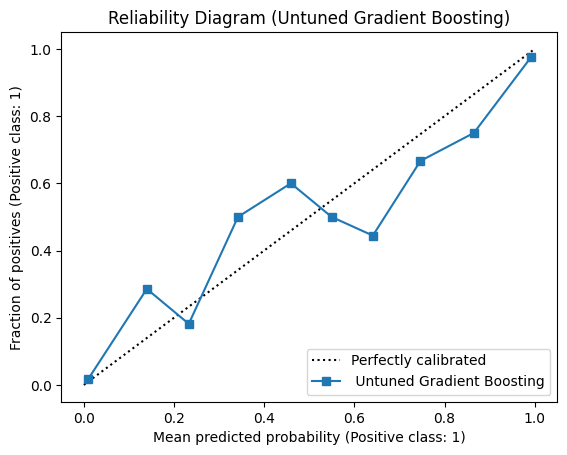

In [29]:
# Set up pipeline
spam_xgb_untuned = create_pipeline(XGBClassifier(random_state=SEED),
                            [], X_spam_train.columns)

# Train the baseline Gradient Boosting model on training data
spam_xgb_untuned.fit(X_spam_train, y_spam_train)

# Draw reliability diagram on the test set
CalibrationDisplay.from_estimator(spam_xgb_untuned, X_spam_test, y_spam_test, n_bins=10, name=" Untuned Gradient Boosting")

plt.title("Reliability Diagram (Untuned Gradient Boosting)")
plt.show()

----------Model Performance on Train Set----------
Brier: 0.0037
Log loss: 0.0215
----------Model Performance on Test Set----------
Brier: 0.0422
Log loss: 0.1491


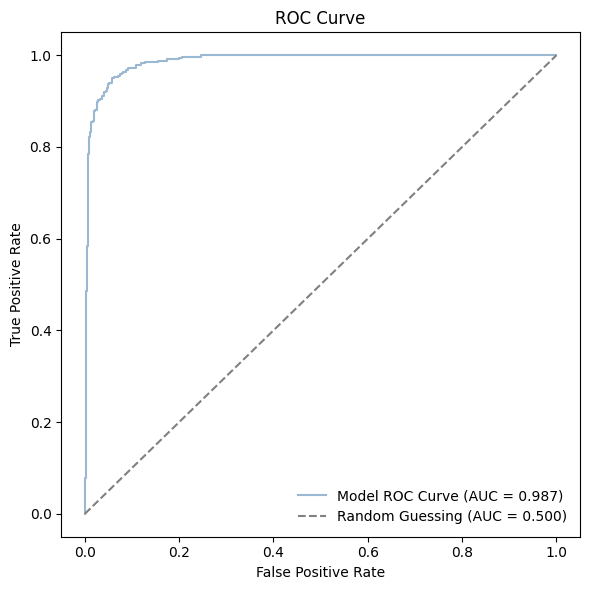

In [30]:
# Evaluate untuned Gradient Boosting performance on dataset
eval_model(spam_xgb_untuned, X_spam_train, X_spam_test, y_spam_train, y_spam_test)

### Evaluation of Untuned Gradient Boosting

**Untuned XGBoost result**:
- Train Set: Brier = **0.0037**, Log loss = **0.0215**
- Test Set: Brier = **0.0422**, Log loss = **0.1491**
- ROC AUC Score: **0.987** on the test set.

The untuned Gradient Boosting has a Test Brier of **0.0422** and log loss of **0.1491**, making it the best of the three untuned models. The train log loss of 0.0215 shows some overfitting that does not hurt test performance much.

As an uncalibrated boosting tree, the predictions lean slightly towards the extremes because trees are built sequentially to correct residual errors (reducing bias). The reliability curve shows deviations from the original, indicating under-confidence or over-confidence in mid-range probabilities.

Its ROC curve is slightly worse than that of Random Forest, but an extremely high test AUC (**0.987**) indicates that it generalizes well.

#### Hyperparameter Tuning

Similar to Logistic Regression and Random Forest, we will tune Gradient Boosting using `BayesSearchCV` on `max_depth`, `learning_rate`, `min_child_weight`, `gamma`, and `subsample`.

In [31]:
# Define the pipeline
xgb_pipeline = create_pipeline(XGBClassifier(random_state=SEED),
                            [], X_spam_train.columns)

# Define a search space
search_space = {
    'classifier__learning_rate': Real(0.01, 1.0, prior='log-uniform'),
    'classifier__max_depth': Integer(3, 10),
    'classifier__min_child_weight': Integer(1, 5),
    'classifier__gamma': Real(0.5, 10),
    'classifier__subsample': Real(0.5, 1.0)
}

# Set up and run BayesSearchCV
opt = BayesSearchCV(estimator=xgb_pipeline, search_spaces=search_space,
                    n_iter=15, cv=5, scoring='neg_log_loss', random_state=SEED, n_jobs=-1)
opt.fit(X_spam_train, y_spam_train)

# Print tuning results
print(f"Best CV Log Loss: {abs(opt.best_score_):.4f}")
print("Best Hyperparameters found:", opt.best_params_)

Best CV Log Loss: 0.1508
Best Hyperparameters found: OrderedDict({'classifier__gamma': 0.5, 'classifier__learning_rate': 0.14193259608884665, 'classifier__max_depth': 10, 'classifier__min_child_weight': 3, 'classifier__subsample': 1.0})


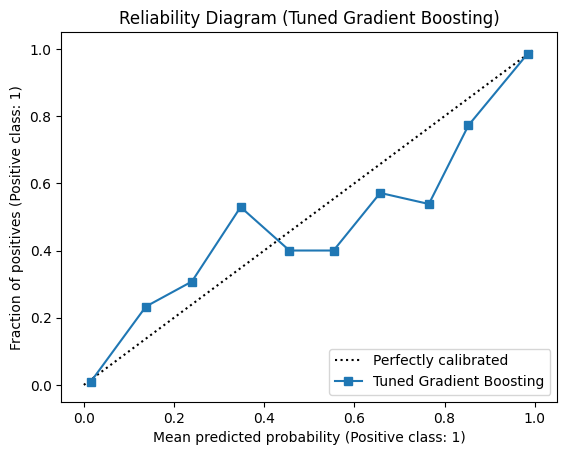

In [32]:
spam_xgb_tuned = opt.best_estimator_

# Draw reliability diagram
CalibrationDisplay.from_estimator(spam_xgb_tuned, X_spam_test, y_spam_test, n_bins=10, name="Tuned Gradient Boosting")

plt.title("Reliability Diagram (Tuned Gradient Boosting)")
plt.show()

----------Model Performance on Train Set----------
Brier: 0.0099
Log loss: 0.0477
----------Model Performance on Test Set----------
Brier: 0.0427
Log loss: 0.1442


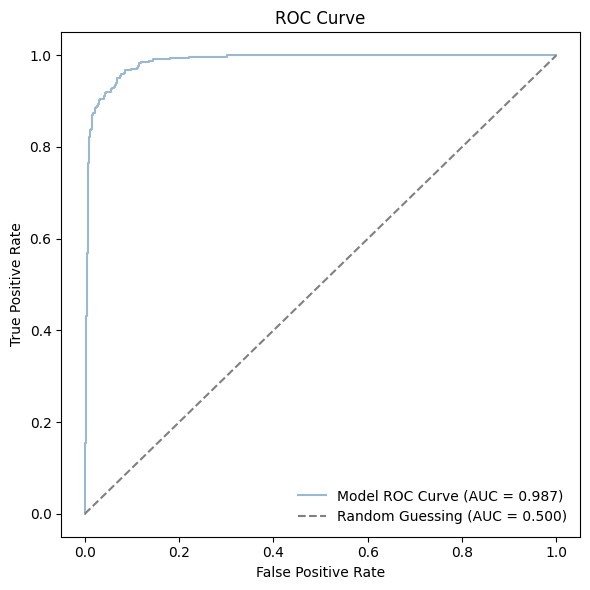

In [33]:
# Evaluate tuned Gradient Boosting performance on dataset
eval_model(spam_xgb_tuned, X_spam_train, X_spam_test, y_spam_train, y_spam_test)

### Evaluation of Tuned Gradient Boosting

**Tuned XGBoost result**:
- Train Set: Brier = **0.0099**, Log loss = **0.0477**
- Test Set: Brier = **0.0427**, Log loss = **0.1442**
- Best CV Log Loss: **0.1508**
- Best Hyperparameters: `gamma=0.5`, `learning_rate ≈ 0.1419`, `max_depth=10`, `min_child_weight=3`, `subsample=1.0`
- ROC AUC Score: **0.987**

Test Brier is **0.0427** and Log Loss is **0.1442**, showing a marginal improvement in test log loss over the untuned baseline (Brier: 0.0422, Log Loss: 0.1491). The gap between the training and testing Log Loss indicates some overfitting in the model.

While it may perform better in terms of log-loss, the tuned model achieves a the same test ROC AUC score of 0.987, demonstrating similar class separation capability as its untuned counterpart.

## 3.3. Online Shoppers Dataset

### 3.3.0. Train-Test Split

In [34]:
X_shop = shoppers_df.drop('Revenue', axis=1)
y_shop = shoppers_df['Revenue']

# Check class balance
print(f"{y_shop.mean():.2%} purchased")

15.63% purchased


Similar to the `spam` data, due to class imbalance, we will perform the train-test split on `shoppers_df` with stratify.

In [35]:
X_shop_train, X_shop_test, y_shop_train, y_shop_test = train_test_split(X_shop, y_shop, test_size=0.2, random_state=SEED, stratify=y_shop)

# Check class balance after split
print(f"Training set: {len(X_shop_train)} rows, {y_shop_train.mean():.2%} purchased")
print(f"Testing set: {len(X_shop_test)} rows, {y_shop_test.mean():.2%} purchased")

Training set: 9764 rows, 15.63% purchased
Testing set: 2441 rows, 15.65% purchased


Shoppers is about 15.6% positive, so the 80/20 split is again stratified to preserve the class ratio.

### 3.3.1. Logistic Regression

Baseline with `class_weight='balanced'`. With a 15% positive rate, balanced weighting inflates predicted purchase probabilities substantially, so we expect poor calibration.

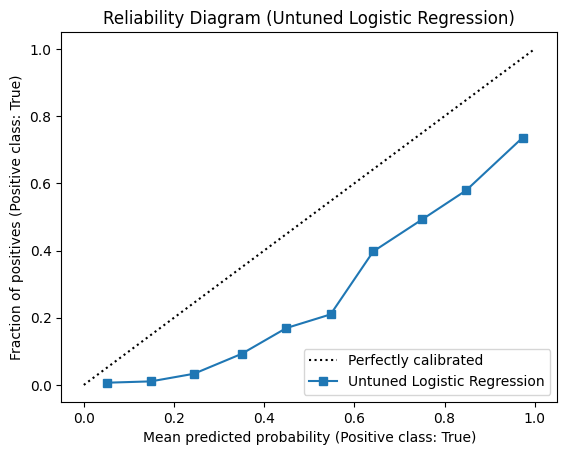

In [36]:
# Set up pipeline
shop_lr_untuned = create_pipeline(LogisticRegression(random_state=SEED, class_weight='balanced', max_iter=1000),
                                  shoppers_cat_features, shoppers_num_features)

# Train the baseline logistic regression model on training data
shop_lr_untuned.fit(X_shop_train, y_shop_train)

# Draw reliability diagram on the test set
CalibrationDisplay.from_estimator(shop_lr_untuned, X_shop_test, y_shop_test, n_bins=10, name="Untuned Logistic Regression")

plt.title("Reliability Diagram (Untuned Logistic Regression)")
plt.show()

----------Model Performance on Train Set----------
Brier: 0.1201
Log loss: 0.4397
----------Model Performance on Test Set----------
Brier: 0.1222
Log loss: 0.4465


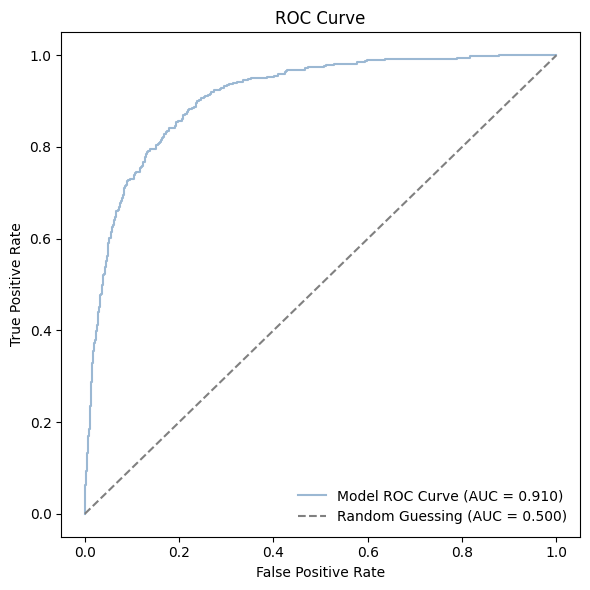

In [37]:
# Evaluate untuned Logistic Regression performance on dataset
eval_model(shop_lr_untuned, X_shop_train, X_shop_test, y_shop_train, y_shop_test)

### Evaluation of Untuned Logistic Regression

**Untuned LR result**:
- Train Set: Brier = **0.1201**, Log loss = **0.4397**
- Test Set: Brier = **0.1222**, Log loss = **0.4465**
- ROC AUC Score: **0.910** on the test set.

Due to severe class imbalance (only 15% positive class) paired with `class_weight='balanced'`, which inflates the probabilities of the minority class, the baseline model greatly overpredicts purchase probabilities. The reliability curve stays consistently below the ideal diagonal line, showing that the predicted probabilities are consistently much higher than the actual empirical fraction of positives.

The AUC is **0.910**, showing respectable discriminative performance despite the severe skewing of the calibrated probability outputs.

#### Hyperparameter Tuning

In [38]:
# Define the pipeline
log_reg_pipeline = create_pipeline(LogisticRegression(random_state=SEED, max_iter=1000),
                                shoppers_cat_features, shoppers_num_features)

# Define the search space
search_space = {
    'classifier__C': Real(1e-4, 1e3, prior='log-uniform'),
    'classifier__penalty': Categorical(['l1', 'l2']),
    'classifier__solver': Categorical(['liblinear', 'saga']),
    'classifier__class_weight': Categorical(['balanced', None])
}

# Set up and run BayesSearchCV
lr_opt = BayesSearchCV(estimator=log_reg_pipeline, search_spaces=search_space,
                       n_iter=15, cv=5, scoring='neg_log_loss', random_state=SEED, n_jobs=-1)
lr_opt.fit(X_shop_train, y_shop_train)

# Output tuning results
print(f"Best CV Log Loss: {abs(lr_opt.best_score_):.4f}")
print("Best Hyperparameters:", lr_opt.best_params_)

Best CV Log Loss: 0.2966
Best Hyperparameters: OrderedDict({'classifier__C': 0.12996535162010367, 'classifier__class_weight': None, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'})


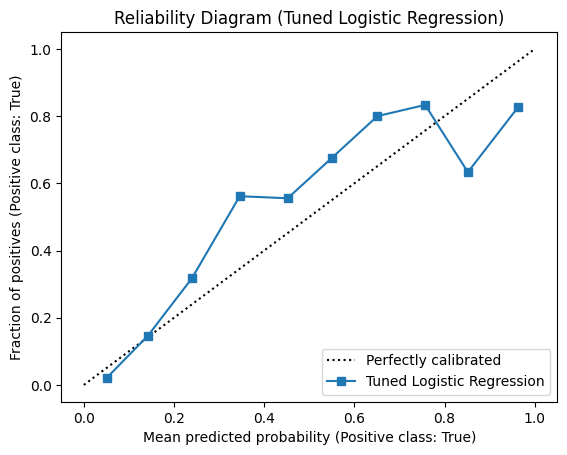

In [39]:
shop_lr_tuned = lr_opt.best_estimator_

# Draw reliability diagram
CalibrationDisplay.from_estimator(shop_lr_tuned, X_shop_test, y_shop_test, n_bins=10, name="Tuned Logistic Regression")

plt.title("Reliability Diagram (Tuned Logistic Regression)")
plt.show()

----------Model Performance on Train Set----------
Brier: 0.0855
Log loss: 0.2936
----------Model Performance on Test Set----------
Brier: 0.0836
Log loss: 0.2888


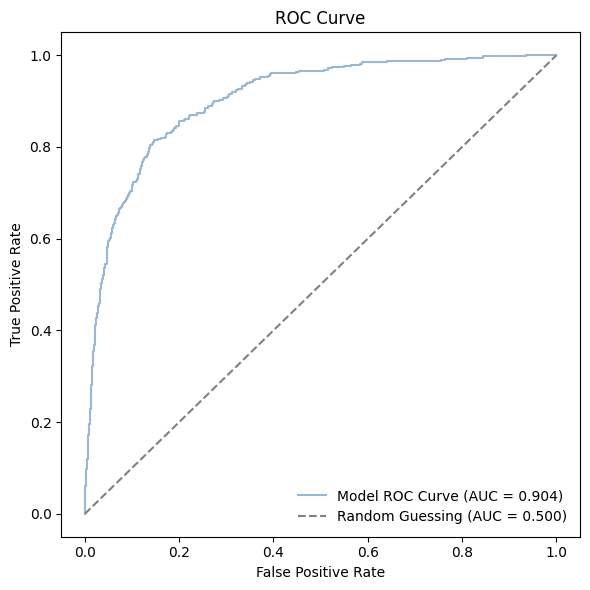

In [40]:
# Evaluate tuned Logistic Regression performance on dataset
eval_model(shop_lr_tuned, X_shop_train, X_shop_test, y_shop_train, y_shop_test)

### Evaluation of Tuned Logistic Regression

**Tuned LR result**:
- Train Set: Brier = **0.0855**, Log loss = **0.2936**
- Test Set: Brier = **0.0836**, Log loss = **0.2888**
- Best CV Log Loss: **0.2966**
- Best Hyperparameters: `C ≈ 0.13`, `class_weight=None`, `penalty='l1'`, `solver='liblinear'`
- ROC AUC Score: **0.904**

Test Brier improves to **0.0836** and Log Loss to **0.2888**, which are significant improvements over the untuned baseline (Brier: 0.1222, Log Loss: 0.4465).
By removing the artificial balance correction (`class_weight=None`), the estimated probabilities are naturally shifted back to match the true 15% base rate. The reliability curve sits significantly closer to the diagonal line, indicating a far better performance than the baseline.

The ROC AUC score is **0.904**, nearly identical to the untuned model, showing that tuning does not always change class discrimination.

### 3.3.2. Random Forest

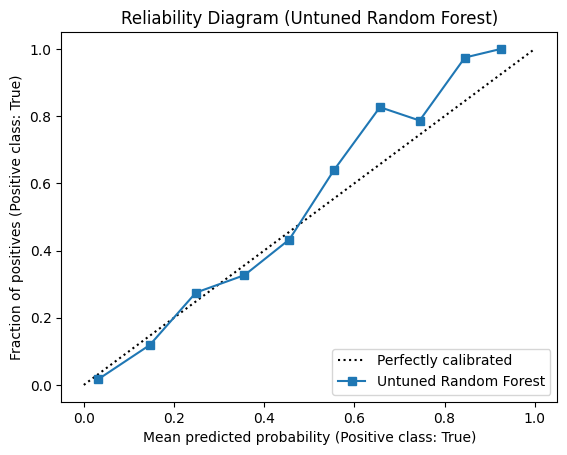

In [41]:
# Set up pipeline
shop_rf_untuned = create_pipeline(RandomForestClassifier(random_state=SEED),
                            shoppers_cat_features, shoppers_num_features)

# Train the baseline Random Forest model on training data
shop_rf_untuned.fit(X_shop_train, y_shop_train)

# Draw reliability diagram on the test set
CalibrationDisplay.from_estimator(shop_rf_untuned, X_shop_test, y_shop_test, n_bins=10, name="Untuned Random Forest")

plt.title("Reliability Diagram (Untuned Random Forest)")
plt.show()

----------Model Performance on Train Set----------
Brier: 0.0102
Log loss: 0.0647
----------Model Performance on Test Set----------
Brier: 0.0724
Log loss: 0.2410


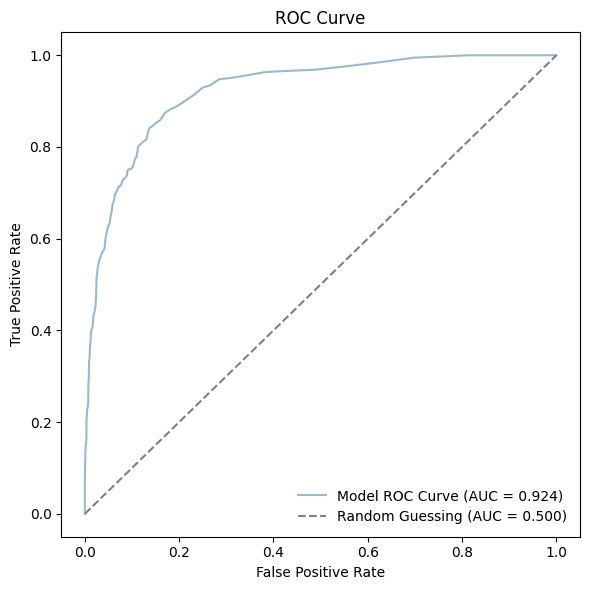

In [42]:
# Evaluate untuned Random Forest performance on dataset
eval_model(shop_rf_untuned, X_shop_train, X_shop_test, y_shop_train, y_shop_test)

### Evaluation of Untuned Random Forest

**Untuned RF result**:
- Train Set: Brier = **0.0102**, Log loss = **0.0647**
- Test Set: Brier = **0.0724**, Log loss = **0.2410**
- ROC AUC Score: **0.924** on the test set.

The untuned Random Forest curve follows very closely to the diagonal, with very few predictions landing in high-probability bins. For the low-probability bins, it aligns moderately well with the diagonal due to the high base rate of the negative samples. Despite beinig well-calibrated, the gap between the training and testing Log Loss shows that the untuned Random Forest exhibits some overfitting.

The model achieves an AUC of **0.924**, demonstrating that the non-linear decision boundaries of the Random Forest capture shopper patterns much better than Logistic Regression.

#### Hyperparameter Tuning

In [43]:
# Define the pipeline
rf_pipeline = create_pipeline(RandomForestClassifier(random_state=SEED),
                            shoppers_cat_features, shoppers_num_features)

# Define a search space
search_space = {
    'classifier__n_estimators': Integer(100, 500),
    'classifier__max_features': Categorical(['sqrt', 'log2', None]),
    'classifier__max_depth': Categorical([None, 10, 15, 20, 30]),
    'classifier__min_samples_split': Integer(2, 10),
    'classifier__min_samples_leaf': Integer(1, 4)
}

# Set up and run BayesSearchCV
opt = BayesSearchCV(estimator=rf_pipeline, search_spaces=search_space,
                    n_iter=15, cv=5, scoring='neg_log_loss', random_state=SEED, n_jobs=-1)
opt.fit(X_shop_train, y_shop_train)

# Print tuning results
print(f"Best CV Log Loss: {abs(opt.best_score_):.4f}")
print("Best Hyperparameters found:", opt.best_params_)

Best CV Log Loss: 0.2293
Best Hyperparameters found: OrderedDict({'classifier__max_depth': 10, 'classifier__max_features': None, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 123})


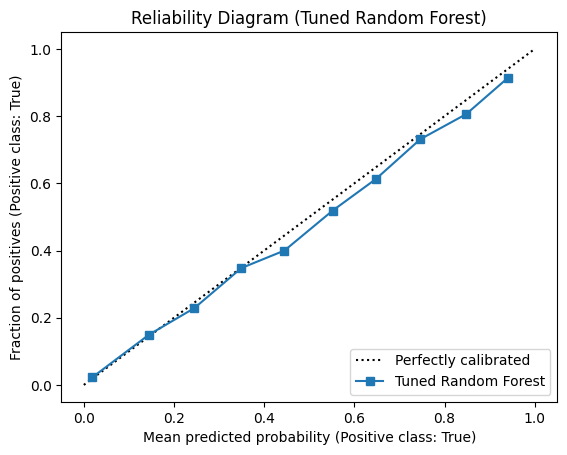

In [44]:
shop_rf_tuned = opt.best_estimator_

# Draw reliability diagram
CalibrationDisplay.from_estimator(shop_rf_tuned, X_shop_test, y_shop_test, n_bins=10, name="Tuned Random Forest")

plt.title("Reliability Diagram (Tuned Random Forest)")
plt.show()

----------Model Performance on Train Set----------
Brier: 0.0404
Log loss: 0.1413
----------Model Performance on Test Set----------
Brier: 0.0709
Log loss: 0.2304


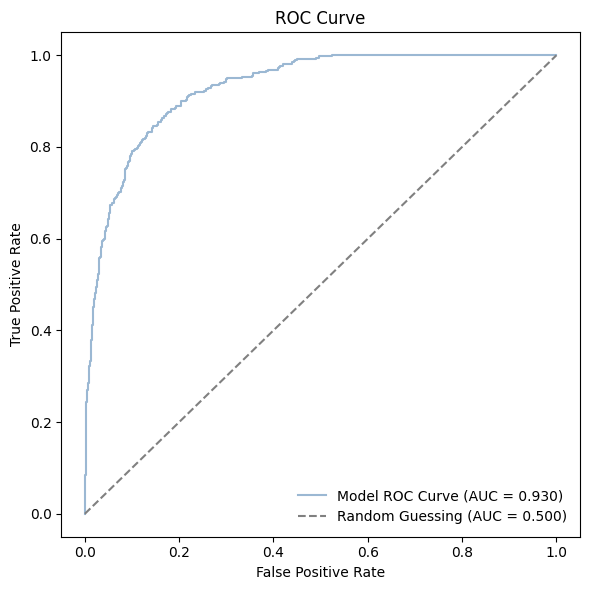

In [45]:
# Evaluate tuned Random Forest performance on dataset
eval_model(shop_rf_tuned, X_shop_train, X_shop_test, y_shop_train, y_shop_test)

### Evaluation of Tuned Random Forest

**Tuned RF result**:
- Train Set: Brier = **0.0404**, Log loss = **0.1413**
- Test Set: Brier = **0.0709**, Log loss = **0.2304**
- Best CV Log Loss: **0.2293**
- Best Hyperparameters: `max_depth=10`, `max_features=None`, `min_samples_leaf=4`, `min_samples_split=10`, `n_estimators=123`
- ROC AUC Score: **0.930**

Test Brier improves to **0.0709** and Log Loss to **0.2304**, which is a decent improvement over the untuned model (Brier: 0.0724, Log Loss: 0.2410). The tuned Random Forest (which restricted the tree depth to 10 and increased the minimum leaf samples) has smoother tree structures. This keeps the predictions more conservative where the probabilities stay clustered closer to the 15% baseline. However, like its untuned counterpart, the tuned Random Forest exhibits some overfitting.

The ROC AUC score is **0.930**, which is a slight increase from the untuned model, confirming that regularizing depth and leaf sizes mitigated some overfitting and improved test discriminative quality.

### 3.3.3. Gradient Boosting

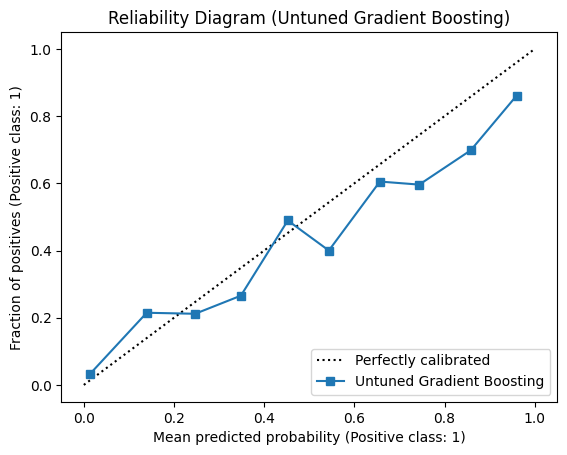

In [46]:
# Set up pipeline
shop_xgb_untuned = create_pipeline(XGBClassifier(random_state=SEED),
                            shoppers_cat_features, shoppers_num_features)

# Train the baseline Random Forest model on training data
shop_xgb_untuned.fit(X_shop_train, y_shop_train)

# Draw reliability diagram on the test set
CalibrationDisplay.from_estimator(shop_xgb_untuned, X_shop_test, y_shop_test, n_bins=10, name="Untuned Gradient Boosting")

plt.title("Reliability Diagram (Untuned Gradient Boosting)")
plt.show()

----------Model Performance on Train Set----------
Brier: 0.0158
Log loss: 0.0704
----------Model Performance on Test Set----------
Brier: 0.0763
Log loss: 0.2544


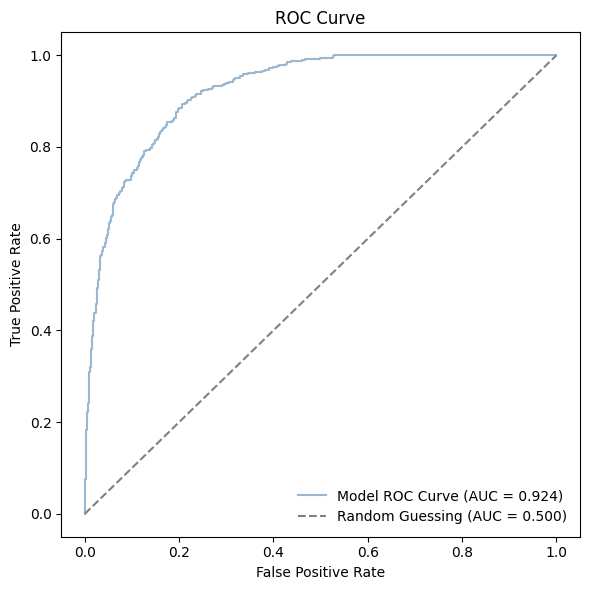

In [47]:
# Evaluate untuned Gradient Boosting performance on dataset
eval_model(shop_xgb_untuned, X_shop_train, X_shop_test, y_shop_train, y_shop_test)

### Evaluation of Untuned Gradient Boosting

**Untuned XGBoost result**:
- Train Set: Brier = **0.0158**, Log loss = **0.0704**
- Test Set: Brier = **0.0763**, Log loss = **0.2544**
- ROC AUC Score: **0.924** on the test set.

The untuned model on this highly imbalanced dataset (15.6% positive) is fit with a high default learning rate (`0.3`). This fast learning rate causes the sequential trees to aggressively adjust for residuals, leading to sharper split decisions. On the test set, this aggressive fitting produces a slightly jagged reliability curve with visible fluctuations across the probability bins. However, this aggressive learning rate also caused some overfitting in the model (as shown by the Log Loss gap between the training and testing evaluation).

It's also worth noting that the untuned Gradient Boosting performs slightly similar to the untuned Random Forest on this dataset, with a higher test Log Loss (0.2544 > 0.2410) and a similar AUC score of 0.924.

#### Hyperparameter Tuning

In [48]:
# Define the pipeline
xgb_pipeline = create_pipeline(XGBClassifier(random_state=SEED),
                            shoppers_cat_features, shoppers_num_features)

# Define a search space
search_space = {
    'classifier__learning_rate': Real(0.01, 1.0, prior='log-uniform'),
    'classifier__max_depth': Integer(3, 10),
    'classifier__min_child_weight': Integer(1, 5),
    'classifier__gamma': Real(0.5, 10),
    'classifier__subsample': Real(0.5, 1.0)
}

# Set up and run BayesSearchCV
opt = BayesSearchCV(estimator=xgb_pipeline, search_spaces=search_space,
                    n_iter=15, cv=5, scoring='neg_log_loss', random_state=SEED, n_jobs=-1)
opt.fit(X_shop_train, y_shop_train)

# Print tuning results
print(f"Best CV Log Loss: {abs(opt.best_score_):.4f}")
print("Best Hyperparameters found:", opt.best_params_)

Best CV Log Loss: 0.2271
Best Hyperparameters found: OrderedDict({'classifier__gamma': 6.073342621062511, 'classifier__learning_rate': 0.2157902941881293, 'classifier__max_depth': 10, 'classifier__min_child_weight': 5, 'classifier__subsample': 0.9402081785342826})


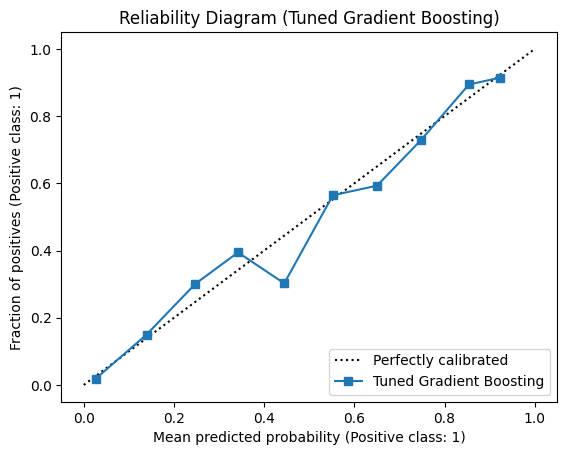

In [49]:
shop_xgb_tuned = opt.best_estimator_

# Draw reliability diagram
CalibrationDisplay.from_estimator(shop_xgb_tuned, X_shop_test, y_shop_test, n_bins=10, name="Tuned Gradient Boosting")

plt.title("Reliability Diagram (Tuned Gradient Boosting)")
plt.show()

----------Model Performance on Train Set----------
Brier: 0.0615
Log loss: 0.2036
----------Model Performance on Test Set----------
Brier: 0.0682
Log loss: 0.2221


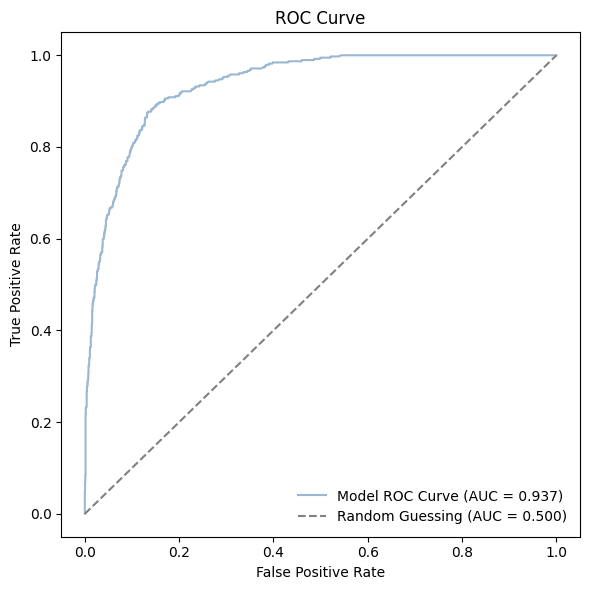

In [50]:
# Evaluate tuned Gradient Boosting performance on dataset
eval_model(shop_xgb_tuned, X_shop_train, X_shop_test, y_shop_train, y_shop_test)

### Evaluation of Tuned Gradient Boosting

**Tuned XGBoost result**:
- Train Set: Brier = **0.0615**, Log loss = **0.2036**
- Test Set: Brier = **0.0682**, Log loss = **0.2221**
- Best CV Log Loss: **0.2271**
- Best Hyperparameters: `gamma ≈ 6.073`, `learning_rate ≈ 0.2158`, `max_depth=10`, `min_child_weight=5`, `subsample ≈ 0.9402`
- ROC AUC Score: **0.937**

The tuned model achieves a Test Brier of **0.0682** and Log Loss of **0.2221**, which are notable improvements over the untuned baseline (Brier: 0.0763, Log Loss: 0.2544). On this highly imbalanced dataset, the reliability diagram for the tuned model shows a slightly jagged curve, though its overall calibration align closer to the diagonal compared to its untuned counterpart.

With a tuned test ROC AUC of **0.937**, Gradient Boosting emerges as the better model of the three for separating purchasers from non-purchasers, showing high sensitivity at low false-positive thresholds.

## 3.4. Summary

Below are the **uncalibrated** untuned and tuned models trained on their respective dataset.

**Spambase**

- `spam_lr_untuned`
- `spam_lr_tuned`
- `spam_rf_untuned`
- `spam_rf_tuned`
- `spam_xgb_untuned`
- `spam_xgb_tuned`

**Online Shoppers**
- `shop_lr_untuned`
- `shop_lr_tuned`
- `shop_rf_untuned`
- `shop_rf_tuned`
- `shop_xgb_untuned`
- `shop_xgb_tuned`